# Course 10: AI Research in 2026
## Session 5: Diffusion language models and the flexibility trap

**Goal:** train a tiny masked diffusion model on a task with several valid solutions and compare left-to-right, confidence-first and random decoding orders on accuracy, diversity and pass@k.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. The 2026 work behind this lab
**Ni et al., "The Flexibility Trap: Rethinking the Value of Arbitrary Order in Diffusion Language Models"** (ICML 2026 Outstanding Paper, arXiv 2601.15165; first posted as "The Flexibility Trap: Why Arbitrary Order Limits Reasoning Potential in Diffusion Language Models") studies masked diffusion language models, which can fill in tokens in any order (Course 3, session 10). The authors report that this freedom can hurt reasoning: decoders that fill in easy, confident tokens first skip the uncertain "forking" tokens (such as "Therefore" or "Since") where a solution branches, so by the time those tokens are filled their uncertainty has collapsed and the set of solutions explored narrows. Their method, JustGRPO, trains with ordinary GRPO while treating the model as left-to-right; they report 89.1% on GSM8K and 45.1% on MATH-500 while keeping parallel decoding at inference.

This lab is a toy illustration, not a reproduction. The model has about 40,000 parameters, the "reasoning" is a four-token chain for adding three digits, and there is no reinforcement learning. The toy asks a narrower question: when the same trained model decodes in different orders, what happens to the forking token, to accuracy and to the diversity of correct solutions?

In [1]:
import itertools
from math import comb
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
torch.set_num_threads(1)          # one thread keeps the numbers reproducible on this machine

### 2. A task with several valid solutions
A problem is three digits $a, b, c$; the answer is $(a+b+c) \bmod 10$. A solution is a 4-token chain: a **strategy** token saying which pair to add first (AB, BC or AC), the pair's sum mod 10, the digit left over, and the answer. Every problem has three correct chains. In the training data the "solvers" prefer the strategies with frequencies 0.6, 0.3 and 0.1, so the strategy token is the forking token: once it is chosen, the rest of the chain is determined.

A sequence has 8 positions: `a b c = S p q y`. The first four are the prompt; the last four are generated.

In [2]:
AB, BC, AC, EQ, MASK = 10, 11, 12, 13, 14           # tokens 0-9 are digits
VOCAB, L = 15, 8
STRAT_P = np.array([0.6, 0.3, 0.1])
NAMES = {AB: "AB", BC: "BC", AC: "AC", EQ: "=", MASK: "_"}

triples = np.array(list(itertools.product(range(10), repeat=3)))
perm = np.random.RandomState(0).permutation(len(triples))
train_tr, test_tr = triples[perm[:800]], triples[perm[800:]]      # 200 problems never seen in training

def all_solutions(tr):                                            # 3 x n x 8: the three correct chains for each problem
    a, b, c = tr[:, 0], tr[:, 1], tr[:, 2]
    y, e = (a + b + c) % 10, np.full_like(a, EQ)
    return np.stack([np.stack([a, b, c, e, np.full_like(a, AB), (a + b) % 10, c, y], 1),
                     np.stack([a, b, c, e, np.full_like(a, BC), (b + c) % 10, a, y], 1),
                     np.stack([a, b, c, e, np.full_like(a, AC), (a + c) % 10, b, y], 1)])

TRAIN = torch.tensor(all_solutions(train_tr))
show = lambda seq: " ".join(NAMES.get(int(t), str(int(t))) for t in seq)
i = next(i for i, (a, b, c) in enumerate(train_tr) if len({a, b, c}) == 3)    # a training problem with three different digits
for s in range(3):
    print(f"strategy used by {STRAT_P[s]:.0%} of solvers: {show(TRAIN[s, i])}")

strategy used by 60% of solvers: 8 5 9 = AB 3 9 2
strategy used by 30% of solvers: 8 5 9 = BC 4 8 2
strategy used by 10% of solvers: 8 5 9 = AC 7 5 2


### 3. A tiny masked diffusion model
Training (as in Course 3, session 10): pick a masking level $t$ between 0.05 and 1, hide each of the 4 answer tokens with probability $t$, and train the network to predict the hidden tokens, weighting the loss by $1/t$. The network is a 2-layer bidirectional transformer with width 48 (every position can see every other). We train three copies with different seeds, because a single training run can mislead.

In [3]:
class Denoiser(nn.Module):
    def __init__(self, d=48, layers=2, heads=4):
        super().__init__()
        self.tok, self.pos = nn.Embedding(VOCAB, d), nn.Embedding(L, d)
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.out = nn.Linear(d, VOCAB)
    def forward(self, x):                                            # logits for the 4 answer positions
        return self.out(self.enc(self.tok(x) + self.pos(torch.arange(L)))[:, 4:])

def train(make_model, steps=1500, seed=0, bs=128, lr=3e-3):
    torch.manual_seed(seed)
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strat_p, losses = torch.tensor(STRAT_P, dtype=torch.float), []
    for step in range(steps):
        x0 = TRAIN[torch.multinomial(strat_p, bs, replacement=True), torch.randint(0, TRAIN.shape[1], (bs,))]
        t = torch.rand(bs, 1) * 0.95 + 0.05
        hidden = torch.rand(bs, 4) < t
        hidden[torch.arange(bs), torch.randint(0, 4, (bs,))] |= ~hidden.any(1)      # hide at least one token
        xt = x0.clone()
        xt[:, 4:][hidden] = MASK
        ce = F.cross_entropy(model(xt).reshape(-1, VOCAB), x0[:, 4:].reshape(-1), reduction="none").view(bs, 4)
        loss = ((ce * hidden).sum(1) / t.squeeze(1)).mean() / 4
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    return model, losses

models = {}
for seed in range(3):
    models[seed], losses = train(Denoiser, seed=seed)
    print(f"seed {seed}: parameters {sum(p.numel() for p in models[seed].parameters()):,}, "
          f"training loss over the last 100 steps {np.mean(losses[-100:]):.3f}")

seed 0: parameters 39,759, training loss over the last 100 steps 0.608


seed 1: parameters 39,759, training loss over the last 100 steps 0.652


seed 2: parameters 39,759, training loss over the last 100 steps 0.473


### 4. Three decoding orders
Generation starts with the 4 answer positions masked and fills one position per step, sampling the token at temperature 1:
- **left-to-right**: always the leftmost masked position, like an autoregressive model;
- **confidence**: the masked position where the model's top probability is highest (easiest first);
- **random**: a masked position chosen at random.

For each of the 200 test problems we draw 16 samples. A sample is **correct** if its whole chain matches one of the three correct chains. We also record when the strategy (fork) token was filled, and the entropy of the model's prediction for it at that moment.

In [4]:
@torch.no_grad()
def decode(model, tr, k, order, temp=1.0, seed=0):
    g = torch.Generator().manual_seed(seed)
    n = len(tr) * k
    x = torch.full((n, L), MASK)
    x[:, :3], x[:, 3] = torch.tensor(np.repeat(tr, k, axis=0)), EQ
    fork_entropy, fork_step = torch.zeros(n), torch.zeros(n)
    for step in range(4):
        logits = model(x).clone()
        logits[..., MASK] = -1e9
        confidence = torch.softmax(logits, -1).max(-1).values
        if order == "left-to-right":
            score = -torch.arange(4).float().expand(n, 4).clone()
        elif order == "confidence":
            score = confidence.clone()
        else:
            score = torch.rand(n, 4, generator=g)
        score[x[:, 4:] != MASK] = -1e9                                  # only masked positions can be chosen
        pos = score.argmax(1)
        tok = torch.multinomial(torch.softmax(logits[torch.arange(n), pos] / temp, -1), 1, generator=g).squeeze(1)
        pf = torch.softmax(logits[:, 0][:, [AB, BC, AC]], -1)            # the model's belief about the strategy token
        fork_entropy = torch.where(pos == 0, -(pf * pf.clamp_min(1e-12).log()).sum(-1), fork_entropy)
        fork_step = torch.where(pos == 0, torch.full_like(fork_step, step + 1.0), fork_step)
        x[torch.arange(n), 4 + pos] = tok
    return x.view(len(tr), k, L), fork_entropy.mean().item(), fork_step.mean().item()

def evaluate(model, order, k=16, tr=test_tr):
    x, fork_H, fork_t = decode(model, tr, k, order)
    sols = torch.tensor(all_solutions(tr)).permute(1, 0, 2)[:, None]          # n x 1 x 3 x 8
    correct = (x[:, :, None, :] == sols).all(-1).any(-1)                       # n x k
    S = x[..., 4]
    share = {NAMES[s]: ((S == s) & correct).sum().item() / max(correct.sum().item(), 1) for s in (AB, BC, AC)}
    distinct = np.mean([len(set(S[i][correct[i]].tolist())) for i in range(len(tr))])
    c = correct.sum(1).numpy()
    pass_k = [np.mean([1 - comb(k - ci, kk) / comb(k, kk) if k - ci >= kk else 1.0 for ci in c]) for kk in range(1, k + 1)]
    return {"answer right": (x[..., 7] == sols[:, :, 0, 7]).float().mean().item(), "pass@1": pass_k[0], "pass@4": pass_k[3],
            "pass@16": pass_k[15], **share, "distinct correct": distinct, "fork step": fork_t, "fork entropy": fork_H, "curve": pass_k}

ORDERS = ["left-to-right", "confidence", "random"]

### 5. First, a model with exact conditionals
Before looking at the trained networks, use an "oracle" that knows the training distribution exactly: for any partly filled chain it returns the true conditional probabilities. If every token is sampled from exact conditionals at temperature 1, any decoding order produces samples from the same distribution (the chain rule works in any order). Watch the strategy shares and the fork entropy.

In [5]:
class Oracle:
    def __call__(self, x):
        n = x.shape[0]
        sols = torch.tensor(all_solutions(x[:, :3].numpy()))[:, :, 4:]              # 3 x n x 4
        consistent = torch.ones(3, n, dtype=torch.bool)
        for j in range(4):
            known = x[:, 4 + j] != MASK
            consistent &= ~known[None] | (sols[:, :, j] == x[None, :, 4 + j])
        w = torch.tensor(STRAT_P, dtype=torch.float)[:, None] * consistent.float()
        w = w / w.sum(0, keepdim=True)
        probs = torch.zeros(n, 4, VOCAB)
        for s in range(3):
            probs.scatter_add_(2, sols[s][:, :, None], w[s][:, None, None].expand(n, 4, 1))
        return torch.log(probs.clamp_min(1e-12))

KEYS = ["answer right", "pass@1", "pass@4", "pass@16", "AB", "BC", "AC", "distinct correct", "fork step", "fork entropy"]
def show_table(rows):
    print(f"{'':16s}" + "".join(f"{k:>17s}" for k in KEYS))
    for name, r in rows.items():
        print(f"{name:16s}" + "".join(f"{r[k]:17.3f}" for k in KEYS))

oracle = {order: evaluate(Oracle(), order) for order in ORDERS}
show_table(oracle)

                     answer right           pass@1           pass@4          pass@16               AB               BC               AC distinct correct        fork step     fork entropy
left-to-right               1.000            1.000            1.000            1.000            0.608            0.296            0.096            2.775            1.000            0.898
confidence                  1.000            1.000            1.000            1.000            0.603            0.292            0.105            2.830            2.353            0.813
random                      1.000            1.000            1.000            1.000            0.594            0.302            0.104            2.840            2.537            0.366


### 6. The trained models
Now the same measurements for the three trained transformers, averaged over the seeds (the per-seed numbers follow).

                     answer right           pass@1           pass@4          pass@16               AB               BC               AC distinct correct        fork step     fork entropy
left-to-right               0.822            0.806            0.970            1.000            0.626            0.286            0.087            2.468            1.000            0.889
confidence                  0.813            0.598            0.880            0.970            0.719            0.228            0.053            1.835            3.156            0.644
random                      0.665            0.502            0.886            0.992            0.661            0.274            0.065            2.157            2.537            0.687

seed 0: pass@1 left-to-right 0.841, confidence 0.495, random 0.474 | distinct correct 2.52, 1.75, 2.14
seed 1: pass@1 left-to-right 0.607, confidence 0.582, random 0.377 | distinct correct 2.15, 1.82, 1.91
seed 2: pass@1 left-to-right 0.970, confidenc

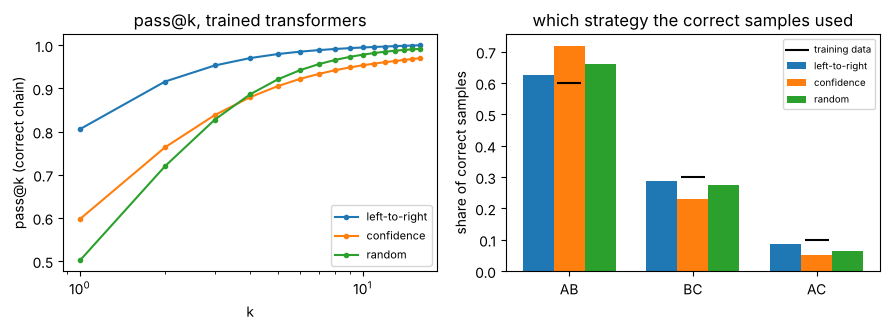

In [6]:
per_seed = {seed: {order: evaluate(models[seed], order) for order in ORDERS} for seed in models}
mean_rows = {order: {k: np.mean([per_seed[s][order][k] for s in models]) for k in KEYS} for order in ORDERS}
show_table(mean_rows)
print()
for seed in models:
    print(f"seed {seed}: pass@1 " + ", ".join(f"{o} {per_seed[seed][o]['pass@1']:.3f}" for o in ORDERS)
          + " | distinct correct " + ", ".join(f"{per_seed[seed][o]['distinct correct']:.2f}" for o in ORDERS))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for order in ORDERS:
    axes[0].plot(range(1, 17), np.mean([per_seed[s][order]["curve"] for s in models], axis=0), "o-", ms=3, label=order)
axes[0].set_xscale("log"); axes[0].set_xlabel("k"); axes[0].set_ylabel("pass@k (correct chain)")
axes[0].set_title("pass@k, trained transformers"); axes[0].legend(fontsize=8)
width = 0.25
for j, order in enumerate(ORDERS):
    axes[1].bar(np.arange(3) + (j - 1) * width, [mean_rows[order][s] for s in ["AB", "BC", "AC"]], width, label=order)
axes[1].scatter(np.arange(3), STRAT_P, c="k", marker="_", s=300, zorder=3, label="training data")
axes[1].set_xticks(range(3), ["AB", "BC", "AC"]); axes[1].set_ylabel("share of correct samples")
axes[1].set_title("which strategy the correct samples used"); axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

### 7. Does the network matter?
The same experiment with a different denoiser: a two-layer MLP that reads the whole one-hot sequence (one seed only).

MLP denoiser: training loss over the last 100 steps 0.338
                     answer right           pass@1           pass@4          pass@16               AB               BC               AC distinct correct        fork step     fork entropy
left-to-right               0.779            0.593            0.937            1.000            0.710            0.207            0.084            2.115            1.000            0.883
confidence                  0.871            0.821            0.979            0.995            0.705            0.212            0.083            2.195            3.241            0.355
random                      0.746            0.625            0.959            1.000            0.631            0.263            0.106            2.445            2.537            0.522


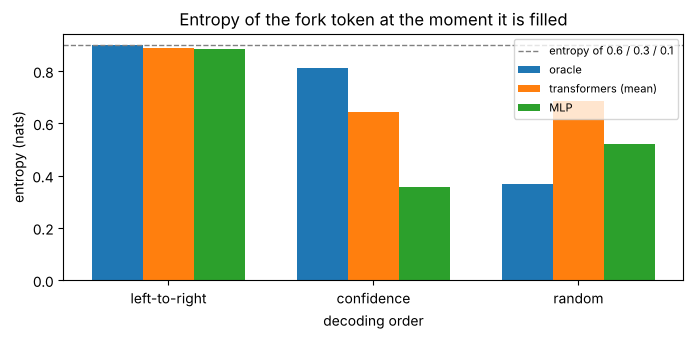

In [7]:
class MLPDenoiser(nn.Module):
    def __init__(self, h=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(L * VOCAB, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 4 * VOCAB))
    def forward(self, x):
        return self.net(F.one_hot(x, VOCAB).float().flatten(1)).view(-1, 4, VOCAB)

mlp, losses = train(MLPDenoiser, steps=2000, seed=0, bs=256, lr=2e-3)
print(f"MLP denoiser: training loss over the last 100 steps {np.mean(losses[-100:]):.3f}")
mlp_rows = {order: evaluate(mlp, order) for order in ORDERS}
show_table(mlp_rows)

fig, ax = plt.subplots(figsize=(8, 3.2))
for j, (label, rows) in enumerate([("oracle", oracle), ("transformers (mean)", mean_rows),
                                   ("MLP", mlp_rows)]):
    ax.bar(np.arange(3) + (j - 1) * 0.25, [rows[o]["fork entropy"] for o in ORDERS], 0.25, label=label)
ax.axhline(-(STRAT_P * np.log(STRAT_P)).sum(), ls="--", c="gray", lw=1, label="entropy of 0.6 / 0.3 / 0.1")
ax.set_xticks(range(3), ORDERS); ax.set_xlabel("decoding order"); ax.set_ylabel("entropy (nats)")
ax.set_title("Entropy of the fork token at the moment it is filled")
ax.legend(fontsize=8)
plt.show()

### 8. A real diffusion language model (NOT RUN here)
LLaDA's sampler offers low-confidence remasking (easiest first) and random remasking, and a block length: with short blocks the answer is filled block by block from left to right, which is close to left-to-right order.

In [ ]:
# NOT RUN: needs a large GPU and the 8B-parameter LLaDA weights (too big for a CPU; about 20 GB of GPU memory or more)
# Also needs `pip install transformers` and generate.py from https://github.com/ML-GSAI/LLaDA (copy it next to this notebook).
import torch
from transformers import AutoModel, AutoTokenizer
from generate import generate      # generate(model, prompt, steps, gen_length, block_length, temperature, cfg_scale, remasking, mask_id)

name = "GSAI-ML/LLaDA-8B-Instruct"
tok = AutoTokenizer.from_pretrained(name, trust_remote_code=True)
model = AutoModel.from_pretrained(name, trust_remote_code=True, torch_dtype=torch.bfloat16).cuda().eval()
question = "A shop sold 48 pens in April and half as many in May. How many pens did it sell in the two months?"
prompt = tok.apply_chat_template([{"role": "user", "content": question}], add_generation_prompt=True, tokenize=False)
ids = tok(prompt, return_tensors="pt")["input_ids"].cuda()
for remasking, block_length in [("low_confidence", 256), ("random", 256), ("low_confidence", 32)]:
    answers = []
    for _ in range(8):
        out = generate(model, ids, steps=256, gen_length=256, block_length=block_length, temperature=1.0, remasking=remasking)
        answers.append(tok.batch_decode(out[:, ids.shape[1]:], skip_special_tokens=True)[0])
    print(remasking, block_length, [a[-30:] for a in answers])
# Next: 8 samples per question on 50 GSM8K questions, then compare pass@1 and pass@8 across the three settings.

### 9. Your turn

In [8]:
# TODO: decode at temperature 0.5 instead of 1.0 (pass temp=0.5 to decode inside evaluate).
# Which order loses more diversity (distinct correct strategies), and does pass@16 change?
print("not done yet")

not done yet


In [9]:
# TODO: parallel decoding. Change decode() so it fills 2 positions per step (the two best by its rule) in 2 steps.
# How often are the two tokens filled together inconsistent with each other? Compare with 1 position per step.
print("not done yet")

not done yet


### What to notice
- With exact conditionals (the oracle), the order changed **when** the fork token was filled (step 1.0, 2.35 and 2.54 on average for left-to-right, confidence and random) and how uncertain it looked at that moment (0.898, 0.813 and 0.366 nats), but not the result: the strategy shares stayed near 0.6 / 0.3 / 0.1 and every sample was correct. Deferring the fork does not, by itself, narrow the set of solutions.
- With the three trained transformers, a trap-like pattern appeared. Confidence-first decoding filled the fork last on average (step 3.16); its pass@1 was 0.598 against 0.806 for left-to-right, its pass@16 was 0.970 against 1.000, and its 16 samples contained 1.84 distinct correct strategies against 2.47, with correct samples leaning harder on the majority strategy (AB 0.719 against 0.626). The direction held in all three seeds. Random order had the lowest pass@1 (0.502) and was in between for diversity (2.16).
- But when the confidence decoder finally filled the fork, the transformers were still unsure about it (0.644 nats, where the oracle's chains would have fixed it). They had not learned well to infer the strategy from a filled-in chain, so many chains came out inconsistent. In this toy the loss comes mostly from conditionals the model learned badly, which is not the same as the mechanism the paper describes, and the toy cannot separate the two.
- With an MLP denoiser the conclusion reversed: confidence-first was the most accurate order (pass@1 0.821 against 0.593 for left-to-right) and no less diverse (2.20 against 2.12 distinct correct strategies). So whether any-order decoding hurts depends, in this toy, on the network and on which conditionals it learned well. The paper's claim is about large diffusion language models and reinforcement learning, which this toy does not test.